# 02 | Limpieza, calidad de datos y variables
**Grupo 6 · Machine Learning · porcentaje de propina en taxis amarillos de NYC (ene-abr 2026)**

Continuación directa de `01_exploracion_inicial.ipynb`. El problema, la población y la partición temporal son los de la propuesta:
predecir, al cerrar el taxímetro de un viaje pagado con tarjeta, `tip_percentage = 100 * tip_amount / fare_amount`.

Este notebook documenta las decisiones que aplica el pipeline (`src/data.py`, `src/features.py`). **Solo usa enero** para mirar
distribuciones y justificar decisiones: marzo es validación y abril sigue reservado.

1. La población de modelado reproduce exactamente los filtros de la entrega 1.
2. Registros sospechosos (reglas incorporadas en el avance 2): se marcan, no se eliminan.
3. Faltantes estructurales.
4. Variables nuevas y por qué los recargos son legítimos.
5. Controles de leakage.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA_DIR = Path(os.environ.get('TAXI_DATA_DIR', ROOT / 'Data'))
OUT, FIG = ROOT / 'outputs', ROOT / 'reports' / 'figures'

from src.data import load_population
from src.features import (add_features, quality_flags, ALL_FEATURES, NUMERIC_FEATURES, ONEHOT_FEATURES,
                          TARGET_ENC_FEATURES, SURCHARGES, FORBIDDEN)
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)

## 1. Población de modelado = población de la entrega 1

`load_population` aplica los mismos pasos 02-09 que `explore` (fecha del mes, tarjeta, tarifa positiva, propina no negativa,
duración positiva, etiqueta disponible antes del corte, duplicados exactos y objetivo finito). Se comprueba contra
`outputs/filtros.csv`, generado en la entrega 1: si los conteos no coinciden, el notebook se detiene.

In [2]:
jan, flow = load_population(DATA_DIR, '2026-01')
previo = pd.read_csv(OUT / 'filtros.csv').query("mes == '2026-01'").reset_index(drop=True)
assert flow[['paso', 'restantes']].equals(previo[['paso', 'restantes']]), 'La población cambió respecto a la entrega 1'
print(f'Enero: {len(jan):,} viajes elegibles, idéntico a la entrega 1.')
display(flow)

Enero: 2,210,259 viajes elegibles, idéntico a la entrega 1.


,mes,paso,restantes,excluidos_en_paso
0,2026-01,01_originales,3724889,0
1,2026-01,02_fecha_del_mes,3724882,7
2,2026-01,03_pago_tarjeta,2249744,1475138
3,2026-01,04_tarifa_positiva_finita,2249454,290
4,2026-01,05_propina_no_negativa_finita,2249454,0
5,2026-01,06_duracion_positiva_finita,2210259,39195
6,2026-01,07_etiqueta_antes_del_corte,2210259,0
7,2026-01,08_sin_duplicados_exactos,2210259,0
8,2026-01,09_objetivo_finito,2210259,0


## 2. Registros sospechosos: marcar en vez de eliminar

El avance 2 propuso eliminar viajes con duración < 1 min o > 180 min, distancia 0 o > 100 mi y velocidad media > 80 mph.
Esas reglas describen errores en **duración y distancia**, no en la etiqueta: la propina y la tarifa de esos viajes siguen
registradas. Eliminarlas cambiaría la población definida en la propuesta y haría incomparables las métricas con la entrega 1.

Decisión final: se conservan todos los viajes, el valor dudoso pasa a faltante dentro de `add_features` y se agrega el indicador
`registro_sospechoso`. Ninguna regla usa el objetivo.

In [3]:
flags = quality_flags(jan)
resumen = pd.DataFrame({'n': flags.sum(), 'pct': (100 * flags.mean()).round(3)})
resumen.loc['alguna regla'] = [int(flags.any(axis=1).sum()), round(100 * flags.any(axis=1).mean(), 3)]
display(resumen)
comparacion = jan.groupby(flags.any(axis=1).map({True: 'sospechoso', False: 'normal'}))['tip_percentage'].describe(
    percentiles=[.1, .5, .9]).round(2)
display(comparacion)

,n,pct
duracion_menor_1_min,17237.0,0.780
duracion_mayor_180_min,1425.0,0.064
distancia_cero_o_faltante,17268.0,0.781
distancia_mayor_100_mi,17.0,0.001
velocidad_mayor_80_mph,287.0,0.013
alguna regla,23805.0,1.077


,count,mean,std,min,10%,50%,90%,max
normal,2186454.0,25.02,17.20,0.0,4.57,26.62,38.06,10869.83
sospechoso,23805.0,67.07,2204.52,0.0,0.00,20.40,42.31,300000.00


Los registros sospechosos son ~1% de cada mes. Su etiqueta existe pero es más ruidosa: mediana más baja y casos extremos
(tarifas casi nulas con propinas de varios dólares). No hay una razón para creer que la propina esté mal registrada, así que
eliminarlos solo quitaría de la evaluación un grupo difícil. Se conservan, se marcan y se analizan aparte en
`04_analisis_errores.ipynb`. La tabla de enero a marzo que usa el pipeline está en `outputs/limpieza_reporte.csv`:

In [4]:
display(pd.read_csv(OUT / 'limpieza_reporte.csv').pivot(index='regla', columns='mes', values='pct'))

mes,2026-01,2026-02,2026-03
regla,,,
distancia_cero_o_faltante,0.781,0.771,0.756
distancia_mayor_100_mi,0.001,0.001,0.001
duracion_mayor_180_min,0.064,0.058,0.029
duracion_menor_1_min,0.780,0.727,0.747
registro_sospechoso (alguna regla),1.077,1.044,1.023
velocidad_mayor_80_mph,0.013,0.014,0.018


## 3. Faltantes estructurales

En la entrega 1, `RatecodeID`, `passenger_count`, `store_and_fwd_flag`, `congestion_surcharge` y `Airport_fee` tenían 27.6% de
faltantes en los registros originales. Al revisar la población con tarjeta:

In [5]:
falt = jan.groupby('VendorID').agg(n=('RatecodeID', 'size'),
                                   pct_ratecode_faltante=('RatecodeID', lambda s: round(100 * s.isna().mean(), 2)),
                                   pct_pasajeros_faltante=('passenger_count', lambda s: round(100 * s.isna().mean(), 2)),
                                   propina_mediana=('tip_percentage', 'median'))
display(falt)
display((100 * jan[SURCHARGES].isna().mean()).round(3).to_frame('pct_faltante_tarjeta'))
pago = pd.read_parquet(DATA_DIR / 'yellow_tripdata_2026-01.parquet', columns=['payment_type', 'RatecodeID'])
display((100 * pago.RatecodeID.isna().groupby(pago.payment_type).mean()).round(2).to_frame('pct_RatecodeID_faltante'))
del pago

,n,pct_ratecode_faltante,pct_pasajeros_faltante,propina_mediana
VendorID,,,,
1,504456,0.0,0.0,25.536481
2,1705803,0.0,0.0,26.764706


,pct_faltante_tarjeta
extra,0.0
mta_tax,0.0
tolls_amount,0.0
improvement_surcharge,0.0
congestion_surcharge,0.0
Airport_fee,0.0
cbd_congestion_fee,0.0


,pct_RatecodeID_faltante
payment_type,
0,100.0
1,0.0
2,0.0
3,0.0
4,0.0


Todos los faltantes pertenecen a `payment_type = 0` (Flex Fare), que la población excluye desde la entrega 1. Dentro de los
viajes con tarjeta no hay faltantes en estas columnas. Aun así el pipeline conserva un tratamiento seguro por si aparecen en otro
mes: `SimpleImputer(strategy='median', add_indicator=True)` ajustado con entrenamiento, `RatecodeID` faltante como categoría propia
y el indicador `ratecode_missing`. Los valores dudosos de duración, distancia y velocidad (sección 2) también pasan por esta
imputación.

## 4. ¿Por qué incorporar los recargos?

La propuesta dejó los recargos fuera "hasta confirmar que se determinan antes de registrar la propina". El diccionario de la TLC
los describe como cargos de la tarifa o del taxímetro. La evidencia en los datos de enero confirma cómo se registra la propina:
si se divide la propina entre el **subtotal antes de propina** (tarifa + recargos, construido sin `total_amount`), aparecen picos
exactos en 20%, 25% y 30%, los botones habituales de la pantalla de pago.

Mediana de propina / subtotal: 20.0 %
Proporción exactamente en 20/25/30% (±0.05): 39.0 / 5.7 / 2.4 %


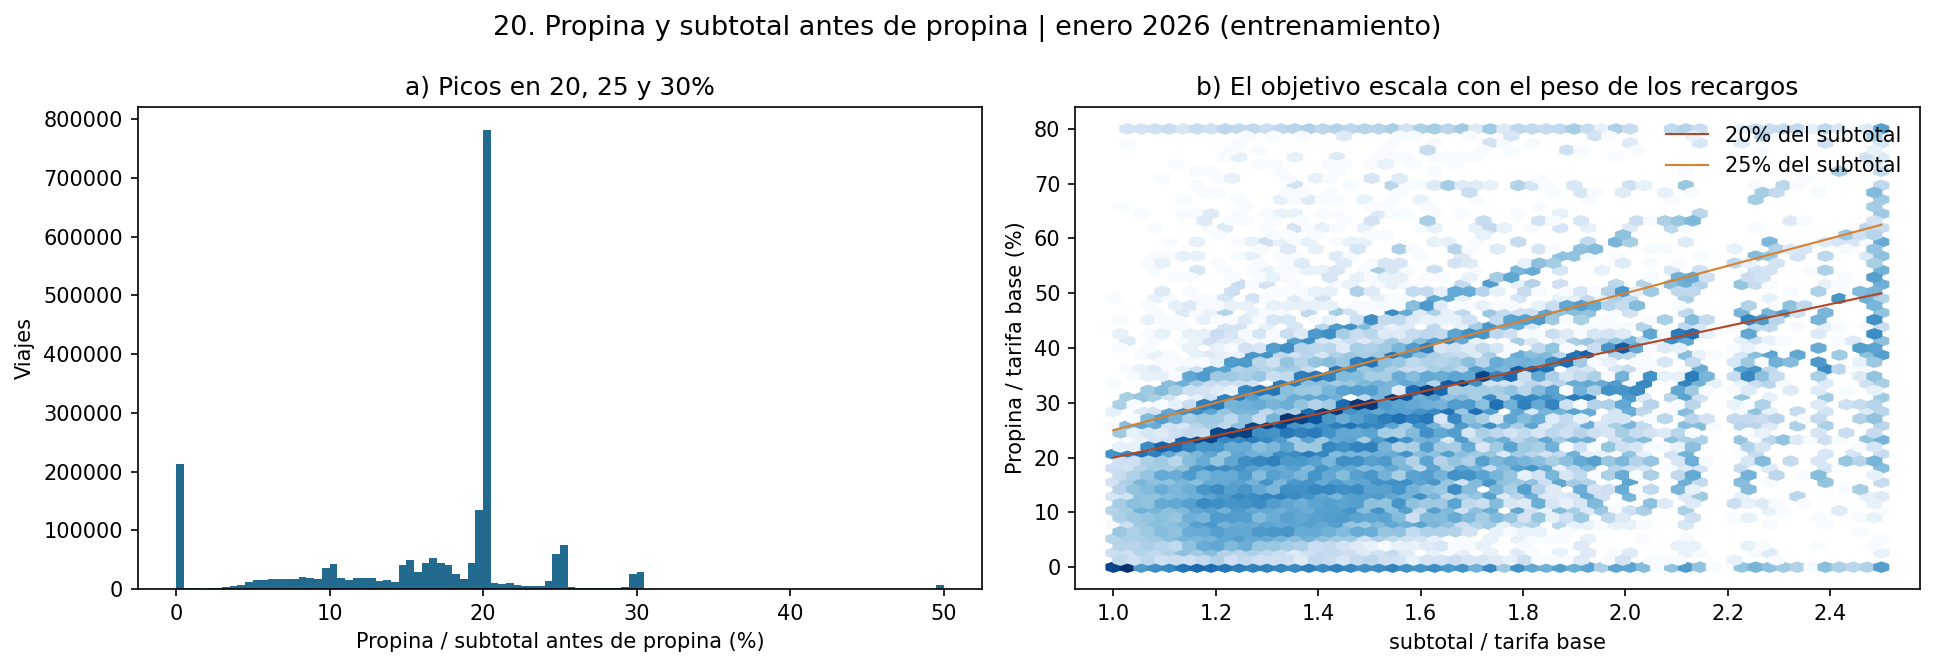

In [6]:
sub = jan['fare_amount'] + jan[SURCHARGES].fillna(0).sum(axis=1)
tip_amount = jan['tip_percentage'] * jan['fare_amount'] / 100   # solo para esta figura descriptiva
sobre_subtotal = 100 * tip_amount / sub
ratio = sub / jan['fare_amount']
print('Mediana de propina / subtotal:', round(sobre_subtotal.median(), 2), '%')
print('Proporción exactamente en 20/25/30% (±0.05):',
      round(100 * sobre_subtotal.sub(20).abs().lt(.05).mean(), 1), '/',
      round(100 * sobre_subtotal.sub(25).abs().lt(.05).mean(), 1), '/',
      round(100 * sobre_subtotal.sub(30).abs().lt(.05).mean(), 1), '%')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(sobre_subtotal.clip(0, 50), bins=np.arange(0, 50.5, .5), color='#236b8e')
axes[0].set(xlabel='Propina / subtotal antes de propina (%)', ylabel='Viajes', title='a) Picos en 20, 25 y 30%')
muestra = jan.sample(200_000, random_state=SEED).index
hb = axes[1].hexbin(ratio[muestra].clip(1, 2.5), jan.loc[muestra, 'tip_percentage'].clip(0, 80), gridsize=55,
                    bins='log', cmap='Blues', mincnt=1)
axes[1].plot([1, 2.5], [20, 50], color='#b34721', lw=1, label='20% del subtotal')
axes[1].plot([1, 2.5], [25, 62.5], color='#d98131', lw=1, label='25% del subtotal')
axes[1].set(xlabel='subtotal / tarifa base', ylabel='Propina / tarifa base (%)',
            title='b) El objetivo escala con el peso de los recargos')
axes[1].legend(frameon=False)
fig.suptitle('20. Propina y subtotal antes de propina | enero 2026 (entrenamiento)', fontsize=13)
fig.tight_layout()
fig.savefig(FIG / '20_propina_sobre_subtotal.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(FIG / '20_propina_sobre_subtotal.png')))

Interpretación: muchos pasajeros eligen un porcentaje **del subtotal**, y el objetivo se define **sobre la tarifa base**. Cuando
los recargos pesan mucho (viajes cortos con congestión, CBD o aeropuerto), el mismo botón de 20% equivale a un porcentaje mayor de
la tarifa. Por eso `ratio_subtotal_fare` es una variable muy informativa y conocida antes de la propina. Su aporte se mide con una
ablación en `03_modelos.ipynb`.

## 5. Variables finales y controles de leakage

In [7]:
X = add_features(jan.sample(100_000, random_state=SEED))
assert list(X.columns) == ALL_FEATURES
assert not FORBIDDEN & set(X.columns), 'Variable prohibida en X'
print('Numéricas:', NUMERIC_FEATURES)
print('One-hot:', ONEHOT_FEATURES)
print('Target encoding (dentro del Pipeline, cross-fitting de 5 particiones):', TARGET_ENC_FEATURES)
display(X.describe().T.round(3))

Numéricas: ['fare_amount', 'log_fare', 'trip_distance', 'duration_min', 'speed_mph', 'passenger_count', 'extra', 'mta_tax', 'tolls_amount', 'improvement_surcharge', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'subtotal_pre_tip', 'ratio_subtotal_fare', 'hour_sin', 'hour_cos', 'is_weekend', 'is_holiday', 'pu_airport', 'do_airport', 'same_zone', 'unknown_zone', 'ratecode_missing', 'registro_sospechoso']
One-hot: ['pickup_hour', 'pickup_weekday', 'RatecodeID_cat', 'VendorID_cat']
Target encoding (dentro del Pipeline, cross-fitting de 5 particiones): ['PULocationID', 'DOLocationID', 'route']


,count,mean,std,min,25%,50%,75%,max
fare_amount,100000.0,19.549,18.296,1.710,9.300,13.500,21.900,450.000
log_fare,100000.0,2.777,0.650,0.997,2.332,2.674,3.131,6.111
trip_distance,100000.0,3.384,4.533,0.000,0.980,1.660,3.250,71.840
duration_min,99170.0,17.064,15.245,1.000,7.617,12.500,20.750,179.383
speed_mph,99164.0,10.663,6.319,0.000,6.800,9.037,12.304,79.475
passenger_count,100000.0,1.249,0.663,0.000,1.000,1.000,1.000,6.000
extra,100000.0,1.520,1.860,0.000,0.000,1.000,2.500,12.500
mta_tax,100000.0,0.492,0.063,0.000,0.500,0.500,0.500,0.500
tolls_amount,100000.0,0.584,2.239,0.000,0.000,0.000,0.000,86.440
improvement_surcharge,100000.0,0.950,0.218,0.000,1.000,1.000,1.000,1.000


| Riesgo | Control aplicado |
|---|---|
| `tip_amount`, `total_amount` como predictores | Lista permitida `ALL_FEATURES` + `assert` sobre `FORBIDDEN` |
| Subtotal que contenga la propina | Se suma tarifa + recargos; nunca se usa `total_amount` |
| Target encoding con información de validación | `TargetEncoder` dentro del `Pipeline`, ajustado solo con entrenamiento y con cross-fitting |
| Imputación con estadísticas futuras | `SimpleImputer` dentro del `Pipeline` |
| Recorte de la cola del objetivo | Cuantil 0.999 aprendido en entrenamiento; validación y test se evalúan sin recorte |
| Elegir con abril | Abril solo se lee en la etapa `test`, después de fijar el modelo con marzo |

## 6. Deriva entre meses


,mes,n,media,mediana,p10,p90,p99,pct_cero,pct_mayor_100
0,2026-01,2210259,25.472,26.566,3.731,38.056,57.083,9.489,0.1860
1,2026-02,2014817,25.231,26.250,3.333,37.692,56.207,9.556,0.1745
2,2026-03,2565402,25.103,26.421,0.165,37.742,56.462,9.891,0.1690


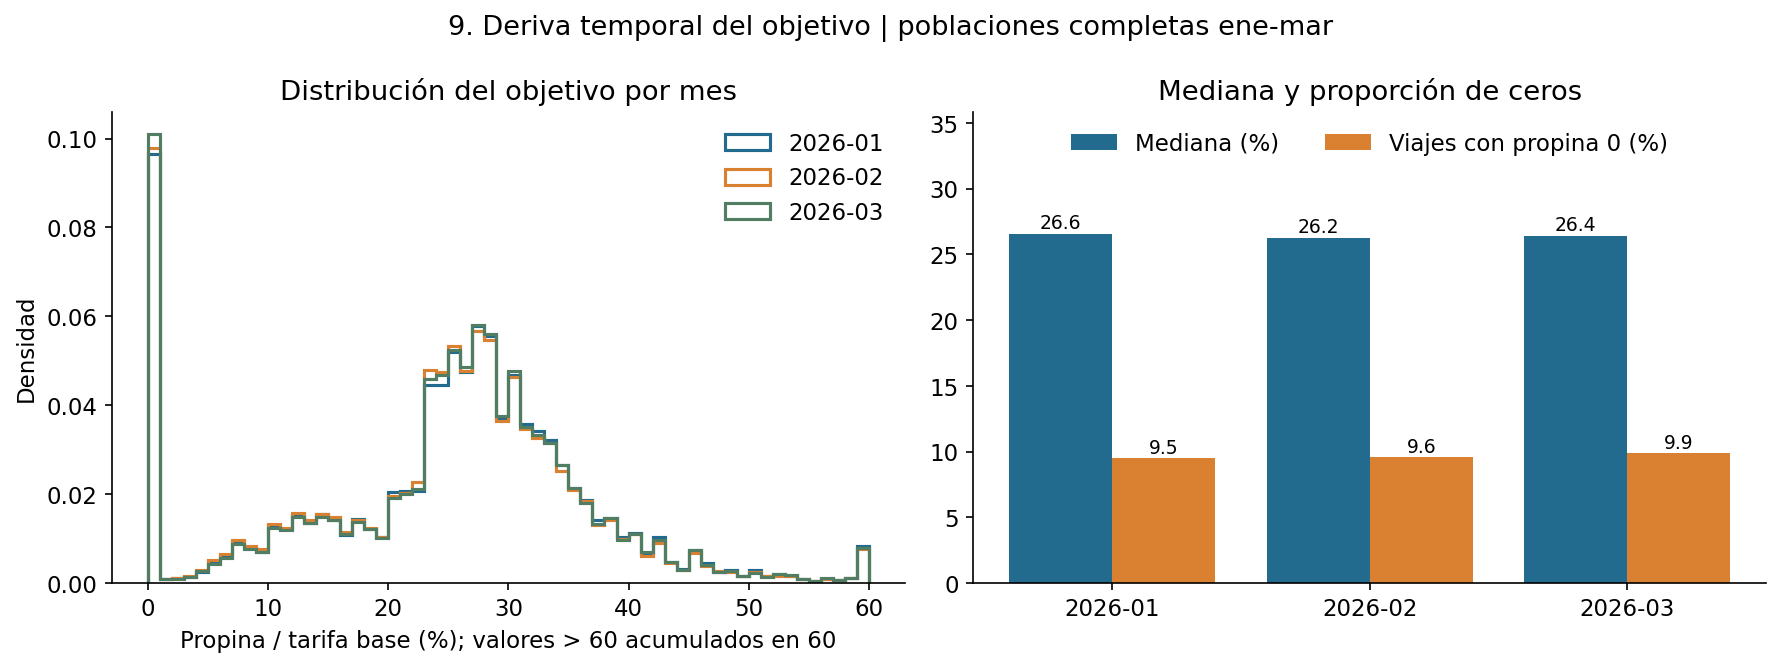

In [8]:
display(pd.read_csv(OUT / 'deriva_mensual.csv'))
display(Image(filename=str(FIG / '09_deriva_objetivo_por_mes.png')))

La forma de la distribución es muy estable entre enero, febrero y marzo: la mediana se mueve menos de medio punto y la
proporción de propinas cero sube levemente en marzo. La partición temporal sigue siendo necesaria (no se mezclan meses), pero no
se observa una deriva que obligue a reponderar.